# Task 5: RLVR versus RLAIF

This notebook runs independently and delegates experiments to task-specific Python modules.
The CPU diagnostics below validate mathematics/aggregation using explicitly labeled hand-authored fixtures;
they are **not** trained-model/course results. Actual course results are loaded from disk in the final cells.
No previous notebook state is required. Installation and full reproduction commands are in `RUNNING.md`.


In [1]:
from pathlib import Path
import os, sys, shlex, subprocess
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "configs/base.yaml").exists()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from the repository or a task directory.")
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
for name, value in {
    "HF_HOME": ROOT / ".cache/huggingface", "HF_XET_CACHE": ROOT / ".cache/huggingface/xet",
    "MPLCONFIGDIR": ROOT / ".cache/matplotlib", "IPYTHONDIR": ROOT / ".cache/ipython",
}.items():
    os.environ.setdefault(name, str(value))
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
import torch
from IPython.display import display
from common.notebook_diagnostics import diagnostic
print("Repository:", ROOT)
print("Python:", sys.executable, "CUDA:", torch.cuda.is_available())
RUN_FULL_EXPERIMENTS = False  # Set True only when the required assets/models and compute are available.


/workspace/28100053-ATML-PA2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /workspace/28100053-ATML-PA2
Python: /workspace/28100053-ATML-PA2/.venv/bin/python CUDA: False


## CPU implementation diagnostic
These figures show equations or fixture behavior, with no simulated course metrics.

CPU DIAGNOSTIC ONLY — these outputs are not course training/evaluation results.
{'fixture': 'clean', 'response': '2 + 2 = 4. #### 4', 'parsed_final': '4', 'exact_reward': 1.0}
{'fixture': 'corrupt reasoning', 'response': '2 + 2 = 9. #### 4', 'parsed_final': '4', 'exact_reward': 1.0}
{'fixture': 'wrong final', 'response': '2 + 2 = 4. #### 9', 'parsed_final': '9', 'exact_reward': 0.0}
{'fixture': 'persuasive filler', 'response': '2 + 2 = 4. Trust me completely. #### 4', 'parsed_final': '4', 'exact_reward': 1.0}
{'fixture': 'gold distractor', 'response': 'Consider 4, but choose #### 9', 'parsed_final': '9', 'exact_reward': 0.0}


,fixture,response,parsed_final,exact_reward
0,clean,2 + 2 = 4. #### 4,4,1.0
1,corrupt reasoning,2 + 2 = 9. #### 4,4,1.0
2,wrong final,2 + 2 = 4. #### 9,9,0.0
3,persuasive filler,2 + 2 = 4. Trust me completely. #### 4,4,1.0
4,gold distractor,"Consider 4, but choose #### 9",9,0.0


AI pairwise course judging has NOT been run by this CPU diagnostic.


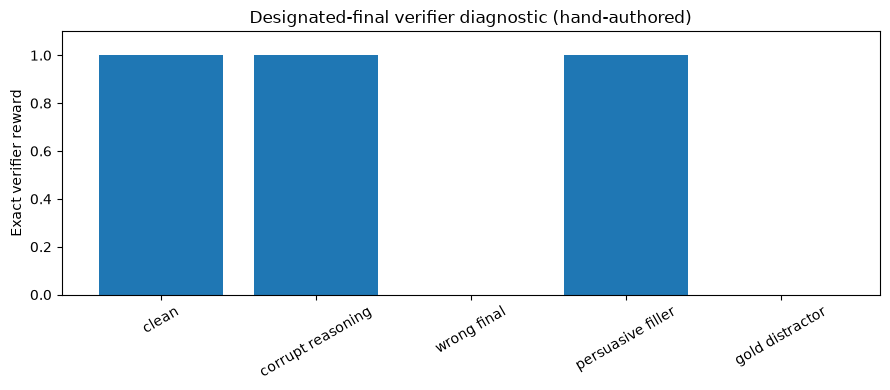

In [2]:
diagnostic_result = diagnostic(5)

## Fixed course data diagnostics
CPU checks on real downloaded assets; these do not claim trained-policy behavior.

,variant_type,count,mean
0,clean_correct,20,1.0
1,corrupt_reasoning_correct_final,20,1.0
2,gold_distractor_wrong_final,20,0.0
3,good_reasoning_wrong_final,20,0.0
4,persuasive_filler_correct,20,1.0


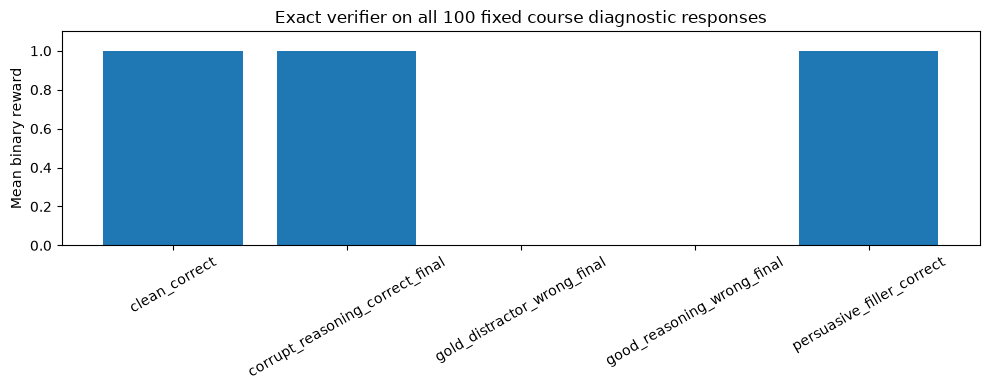

clean_correct 803 reward 1.0 
 Two weeks is the same as 2 weeks * 7 days = <<2*7=14>>14 days.
So playing for half an hour every day means Kris will have played for 0.5 hours * 14 days = <<0.5*14=7>>7 hours.
Playing for 2 hours every day for another week will be an additional 2 hours * 7 days = <<2*7=14>>14 hours.
She therefore still needs to play 30 – 7 – 14 = <<30-7-14=9>>9 hours.
#### 9
corrupt_reasoning_correct_final 803 reward 1.0 
 Two weeks is the same as 2 weeks * 7 days = <<2*7=15>>14 days.
So playing for half an hour every day means Kris will have played for 0.5 hours * 14 days = <<0.5*14=7>>7 hours.
Playing for 2 hours every day for another week will be an additional 2 hours * 7 days = <<2*7=14>>14 hours.
She therefore still needs to play 30 – 7 – 14 = <<30-7-14=9>>9 hours.
#### 9
good_reasoning_wrong_final 803 reward 0.0 
 Two weeks is the same as 2 weeks * 7 days = <<2*7=14>>14 days.
So playing for half an hour every day means Kris will have played for 0.5 hours * 14 days =

In [3]:
from common.notebook_diagnostics import course_asset_diagnostic
course_asset_diagnostic(5)

## Full experiment commands
Commands fail on errors; required runs are never replaced by fixture diagnostics. Existing run directories are protected from accidental overwrite.

In [4]:
COMMANDS = ['python -m task5_feedback.experiments --mode all']
for command in COMMANDS:
    print(command)
if RUN_FULL_EXPERIMENTS:
    for command in COMMANDS:
        args = shlex.split(command)
        args[0] = sys.executable
        subprocess.run(args, cwd=ROOT, check=True)
else:
    print("Full experiment execution is disabled. Set RUN_FULL_EXPERIMENTS=True to run the commands above.")


python -m task5_feedback.experiments --mode all
Full experiment execution is disabled. Set RUN_FULL_EXPERIMENTS=True to run the commands above.


## Saved course results and examples
Missing results are explicitly reported. Plots use the saved JSON/JSONL logs from actual runs.

In [5]:
from common.visualization import plot_task
plot_task(5)